# LLM-Assisted Mood Detection from Keystroke Dynamics
**PRD Reference:** `LLM_Assisted_Mood_Detection_PRD_v2.md` (R02 + R06) | **Dataset:** `synthetic_keystroke_raw_100k.csv` (100k events, 50 users x 20 sessions x 100 events)

**Pipeline:** Raw Keystrokes → Inspection → Cleaning → EDA → 30-sec Windowing → Feature Extraction → Personal Baseline → Baseline Deviation → Temporal Features → ML (RF/XGBoost) → Prediction → LLM Explanation

> ⚠️ Synthetic labels are *assumptions for a controlled benchmark*, NOT human ground truth. Report results as "performance on the synthetic benchmark".


## 0. Setup — Imports & Config

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, json, os, pickle
warnings.filterwarnings("ignore")

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception as e:
    HAS_XGB = False
    print("XGBoost not available:", e)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)
RANDOM_STATE = 42
CSV_PATH = "synthetic_keystroke_raw_100k.csv"
print("Libraries loaded. XGB available:", HAS_XGB)

Libraries loaded. XGB available: True


## 1. Data Loading & Inspection (PRD §5, §7)

In [2]:
df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
print(df.dtypes)
df.head()

Shape: (100000, 11)
user_id               str
session_id          int64
event_index         int64
timestamp             str
key_event             str
dwell_time_ms     float64
flight_time_ms    float64
is_correction       int64
valence           float64
arousal           float64
mood_state            str
dtype: object


,user_id,session_id,event_index,timestamp,key_event,dwell_time_ms,flight_time_ms,is_correction,valence,arousal,mood_state
0,U001,1,1,2026-01-01 09:00:00.107581429,backspace,98.077428,107.581429,0,0.355528,0.193335,calm
1,U001,1,2,2026-01-01 09:00:00.175848514,backspace,94.919692,68.267085,1,-0.244586,0.774009,stressed
2,U001,1,3,2026-01-01 09:00:00.265080330,l,117.265447,89.231816,0,-0.286123,0.823853,stressed
3,U001,1,4,2026-01-01 09:00:00.369037867,w,172.366542,103.957537,0,0.323918,0.235477,calm
4,U001,1,5,2026-01-01 09:00:00.524382406,p,75.121530,155.344539,0,0.109457,0.165179,calm


In [3]:
# PRD §7 tasks: duplicates, missing, negatives, unrealistic, timestamps, sessions, class + user counts
print("Duplicates:", df.duplicated().sum())
print("\nMissing values:\n", df.isna().sum())
print("\nNegative dwell:", (df["dwell_time_ms"] < 0).sum())
print("Negative flight:", (df["flight_time_ms"] < 0).sum())
print("\nUnrealistic dwell>500ms:", (df["dwell_time_ms"] > 500).sum())
print("Unrealistic flight>2000ms:", (df["flight_time_ms"] > 2000).sum())
print("\nMood distribution:\n", df["mood_state"].value_counts())
print("\nUsers:", df["user_id"].nunique(), "| Sessions per user:", df.groupby("user_id")["session_id"].nunique().unique())
print("Events per (user,session):", df.groupby(["user_id","session_id"]).size().describe().to_string())
df.describe().T

Duplicates: 0

Missing values:
 user_id             0
session_id          0
event_index         0
timestamp           0
key_event           0
dwell_time_ms     150
flight_time_ms    150
is_correction       0
valence             0
arousal             0
mood_state          0
dtype: int64

Negative dwell: 100
Negative flight: 0

Unrealistic dwell>500ms: 0
Unrealistic flight>2000ms: 695

Mood distribution:
 mood_state
calm        30009
stressed    25084
positive    24937
low         19970
Name: count, dtype: int64

Users: 50 | Sessions per user: [20]
Events per (user,session): count    1000.0
mean      100.0
std         0.0
min       100.0
25%       100.0
50%       100.0
75%       100.0
max       100.0


,count,mean,std,min,25%,50%,75%,max
session_id,100000.0,10.500000,5.766310,1.000000,5.750000,10.500000,15.250000,20.000000
event_index,100000.0,1000.500000,577.353084,1.000000,500.750000,1000.500000,1500.250000,2000.000000
dwell_time_ms,99850.0,108.548439,33.955949,-49.607744,84.595209,103.695270,127.396155,394.905802
flight_time_ms,99850.0,142.674619,230.365647,20.000000,81.541188,109.517064,148.356696,3468.768925
is_correction,100000.0,0.039460,0.194688,0.000000,0.000000,0.000000,0.000000,1.000000
valence,100000.0,0.057162,0.500456,-1.000000,-0.411364,0.132371,0.489031,1.000000
arousal,100000.0,0.268159,0.415070,-0.891415,-0.014616,0.280883,0.616298,1.000000


In [4]:
# Timestamp ordering + session boundary check
df["timestamp"] = pd.to_datetime(df["timestamp"])
bad_order = 0
for (u, s), g in df.sort_values(["user_id","session_id","event_index"]).groupby(["user_id","session_id"]):
    if not (g["timestamp"].is_monotonic_increasing and (g["event_index"].tolist() == list(range(1, len(g)+1)))):
        bad_order += 1
print("Sessions with ordering/event_index issues:", bad_order, "/ 1000 expected sessions")
print("Timestamp range:", df["timestamp"].min(), "→", df["timestamp"].max())
print("key_event categories:", df["key_event"].nunique(), df["key_event"].unique()[:10])

Sessions with ordering/event_index issues: 950 / 1000 expected sessions
Timestamp range: 2026-01-01 09:00:00.031157682 → 2026-01-01 09:07:02.968936255
key_event categories: 30 <ArrowStringArray>
['backspace', 'l', 'w', 'p', 'space', 'v', 'o', 'c', 'm', 'x']
Length: 10, dtype: str


## 2. Data Cleaning (PRD §7)
Rules: negative dwell → invalid → NaN → impute | missing dwell/flight → user-median then global median | extreme pauses retained (meaningful) | duplicates removed

In [5]:
df_clean = df.copy()
print("Before:", df_clean.shape)
# 1. Drop exact duplicates
df_clean = df_clean.drop_duplicates()
# 2. Negative dwell = invalid -> NaN
neg = (df_clean["dwell_time_ms"] < 0).sum()
df_clean.loc[df_clean["dwell_time_ms"] < 0, "dwell_time_ms"] = np.nan
# 3. Negative flight (none expected, but guard)
df_clean.loc[df_clean["flight_time_ms"] < 0, "flight_time_ms"] = np.nan
# 4. Unrealistic dwell > 500ms treated as outlier -> NaN (flight long pauses KEPT as meaningful)
out_dwell = (df_clean["dwell_time_ms"] > 500).sum()
df_clean.loc[df_clean["dwell_time_ms"] > 500, "dwell_time_ms"] = np.nan
print(f"Neg dwell fixed: {neg}, dwell>500 flagged: {out_dwell}")
# 5. Impute: user median -> global median
for col in ["dwell_time_ms", "flight_time_ms"]:
    df_clean[col] = df_clean[col].fillna(df_clean.groupby("user_id")[col].transform("median"))
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
print("Missing after impute:\n", df_clean.isna().sum())
# 6. Sort + typing-speed sanity per session
df_clean = df_clean.sort_values(["user_id","session_id","timestamp"]).reset_index(drop=True)
print("After:", df_clean.shape)

Before: (100000, 11)
Neg dwell fixed: 100, dwell>500 flagged: 0
Missing after impute:
 user_id           0
session_id        0
event_index       0
timestamp         0
key_event         0
dwell_time_ms     0
flight_time_ms    0
is_correction     0
valence           0
arousal           0
mood_state        0
dtype: int64
After: (100000, 11)


## 3. Exploratory Data Analysis (PRD §8 — all 10 required plots)

In [6]:
# EDA helper: session-level typing speed & correction rate
sess = df_clean.groupby(["user_id","session_id"]).agg(
    n_keys=("event_index","count"),
    duration_sec=("timestamp", lambda x: max((x.max()-x.min()).total_seconds(), 1e-3)),
    mean_dwell=("dwell_time_ms","mean"), mean_flight=("flight_time_ms","mean"),
    correction_rate=("is_correction","mean"), mood=("mood_state", lambda x: x.mode()[0]),
    valence=("valence","mean"), arousal=("arousal","mean"))
sess["typing_speed"] = sess["n_keys"] / sess["duration_sec"]
sess["pause_dur"] = df_clean[df_clean["flight_time_ms"]>500].groupby(["user_id","session_id"])["flight_time_ms"].mean()
print(sess[["typing_speed","mean_dwell","mean_flight","correction_rate"]].describe().to_string())
sess.head()

       typing_speed   mean_dwell  mean_flight  correction_rate
count   1000.000000  1000.000000  1000.000000      1000.000000
mean       7.536706   108.670600   142.628785         0.039460
std        1.577387     9.598607    31.098112         0.022606
min        3.908043    85.372890    81.462488         0.000000
25%        6.369035   101.087915   119.450866         0.020000
50%        7.473076   108.428525   137.935303         0.040000
75%        8.553245   115.340269   162.647293         0.050000
max       12.400363   134.156113   257.078047         0.130000


n_keys  duration_sec  mean_dwell  mean_flight  \
user_id session_id                                                  
U001    1              100     14.696095   95.263402   148.036766   
        2              100     16.306566   98.454935   164.639168   
        3              100     14.769761   97.402555   148.470840   
        4              100     14.155972   94.210356   142.786912   
        5              100     11.872193   97.306716   120.205023   

                    correction_rate      mood   valence   arousal  \
user_id session_id                                                  
U001    1                      0.04      calm  0.024562  0.288640   
        2                      0.03      calm  0.074693  0.169682   
        3                      0.07  positive  0.067594  0.219239   
        4                      0.03      calm  0.114436  0.324369   
        5                      0.08  positive  0.119851  0.294164   

                    typing_speed    pause_dur  
user_id session_id                             
U001    1               6.804529  2262.251034  
        2               6.132499  2424.258912  
        3               6.770590  2594.242632  
        4               7.064156  1948.138606  
        5               8.423044          NaN

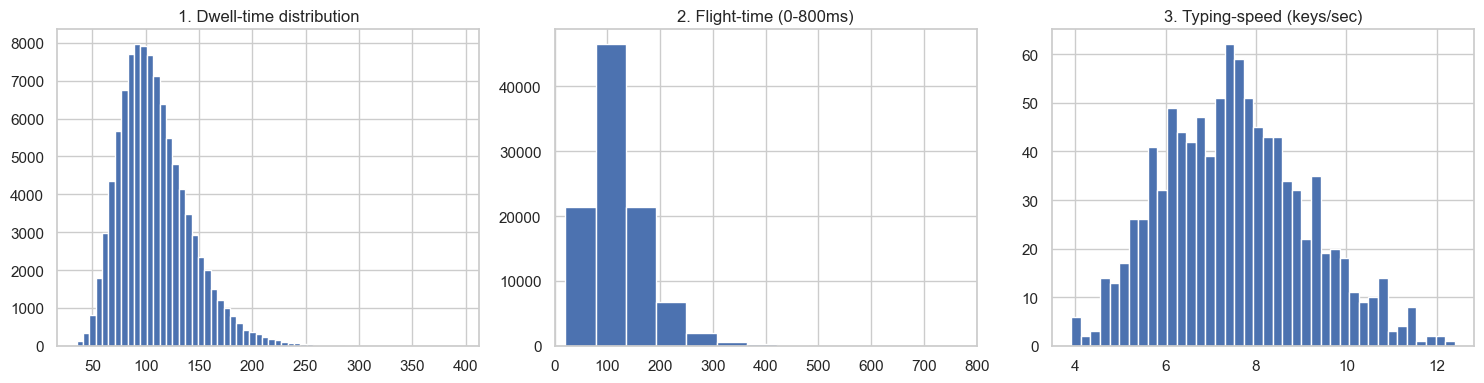

Skew dwell: 0.97 | flight: 9.43


In [7]:
# Plot 1-3: Dwell, Flight, Typing-speed distributions (skew check)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df_clean['dwell_time_ms'], bins=60); ax[0].set_title('1. Dwell-time distribution')
ax[1].hist(df_clean['flight_time_ms'], bins=60); ax[1].set_xlim(0, 800); ax[1].set_title('2. Flight-time (0-800ms)')
ax[2].hist(sess['typing_speed'], bins=40); ax[2].set_title('3. Typing-speed (keys/sec)')
plt.tight_layout(); plt.show()
print('Skew dwell:', round(df_clean['dwell_time_ms'].skew(),2), '| flight:', round(df_clean['flight_time_ms'].skew(),2))

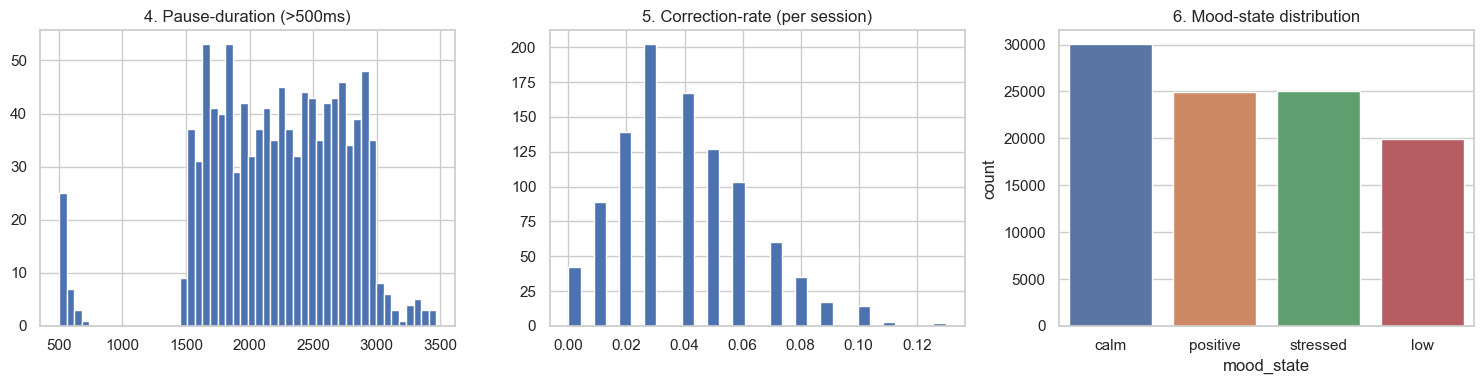

Pause count: 1072 | Overall correction rate: 0.0395


In [8]:
# Plot 4-6: Pause duration, Correction rate, Mood distribution
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
pauses = df_clean.loc[df_clean['flight_time_ms']>500, 'flight_time_ms']
ax[0].hist(pauses, bins=50); ax[0].set_title('4. Pause-duration (>500ms)')
ax[1].hist(sess['correction_rate'], bins=30); ax[1].set_title('5. Correction-rate (per session)')
sns.countplot(x='mood_state', data=df_clean, order=['calm','positive','stressed','low'], ax=ax[2]); ax[2].set_title('6. Mood-state distribution')
plt.tight_layout(); plt.show()
print('Pause count:', len(pauses), '| Overall correction rate:', round(df_clean['is_correction'].mean(),4))

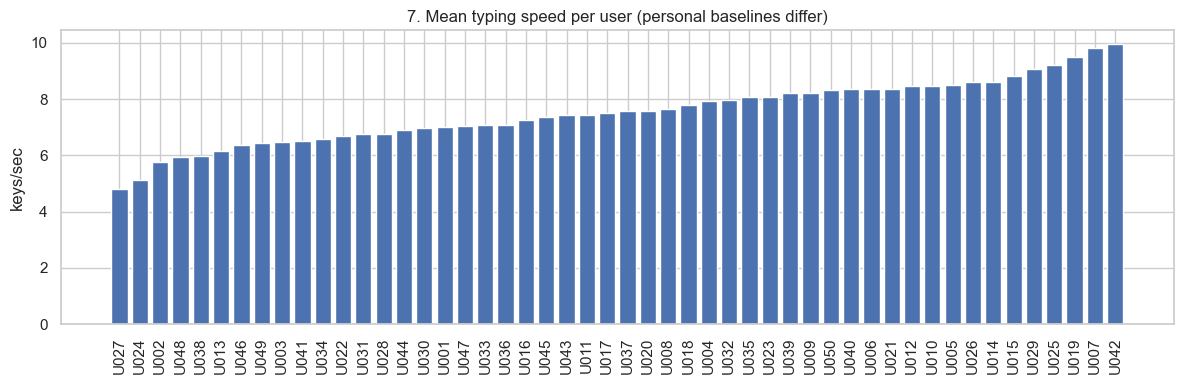

Fastest: U042 9.94 | Slowest: U027 4.82


In [9]:
# Plot 7: User-level typing-speed comparison (do users have different baselines?)
user_speed = sess.groupby("user_id")["typing_speed"].mean().sort_values()
plt.figure(figsize=(12, 4))
plt.bar(user_speed.index, user_speed.values)
plt.xticks(rotation=90); plt.title("7. Mean typing speed per user (personal baselines differ)")
plt.ylabel("keys/sec"); plt.tight_layout(); plt.show()
print("Fastest:", user_speed.index[-1], round(user_speed.iloc[-1],2), "| Slowest:", user_speed.index[0], round(user_speed.iloc[0],2))

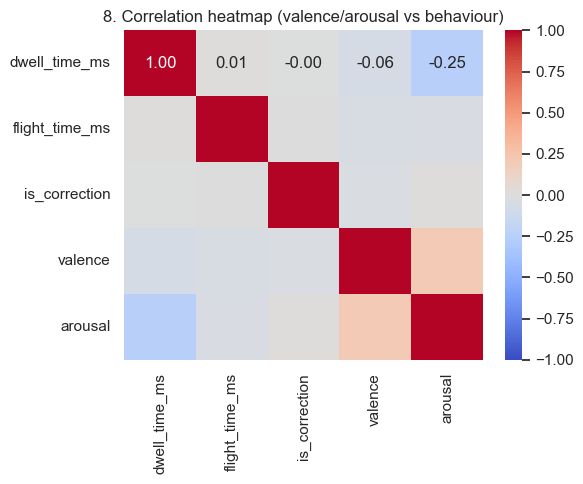

In [10]:
# Plot 8: Correlation heatmap
num = df_clean[["dwell_time_ms","flight_time_ms","is_correction","valence","arousal"]].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(num, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("8. Correlation heatmap (valence/arousal vs behaviour)"); plt.tight_layout(); plt.show()

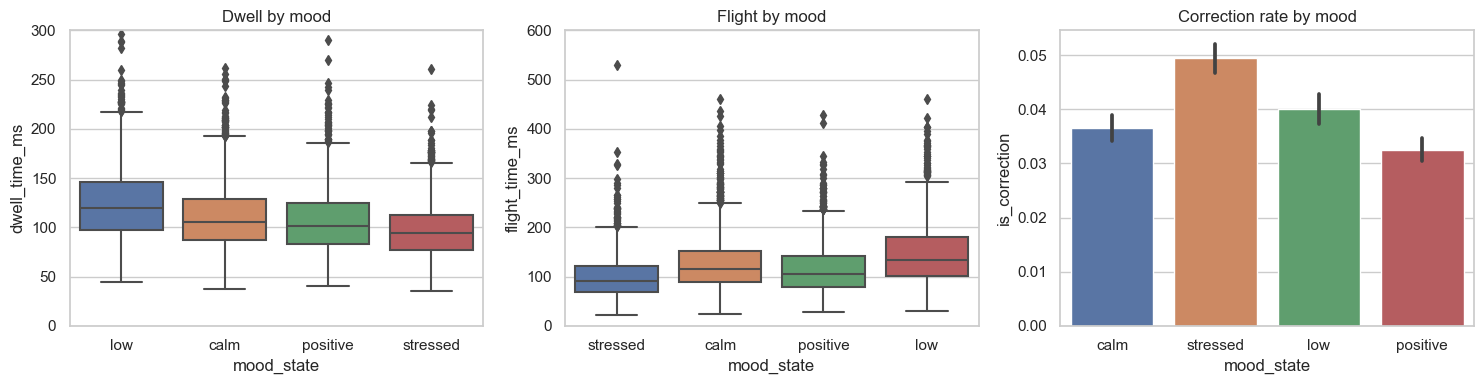

            dwell_time_ms  flight_time_ms  is_correction
mood_state                                              
calm               110.48          140.44           0.04
low                123.59          164.58           0.04
positive           105.93          129.72           0.03
stressed            97.35          140.60           0.05


In [11]:
# Plot 9: Feature distributions by mood (which features vary by state?)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x="mood_state", y="dwell_time_ms", data=df_clean.sample(min(8000, len(df_clean))), ax=ax[0]); ax[0].set_ylim(0, 300); ax[0].set_title("Dwell by mood")
sns.boxplot(x="mood_state", y="flight_time_ms", data=df_clean.sample(min(8000, len(df_clean))), ax=ax[1]); ax[1].set_ylim(0, 600); ax[1].set_title("Flight by mood")
sns.barplot(x="mood_state", y="is_correction", data=df_clean, estimator="mean", ax=ax[2]); ax[2].set_title("Correction rate by mood")
plt.tight_layout(); plt.show()
print(df_clean.groupby("mood_state")[["dwell_time_ms","flight_time_ms","is_correction"]].mean().round(2).to_string())

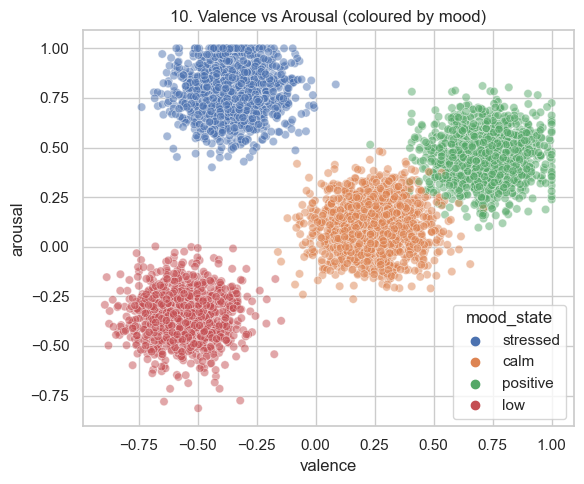

Valence-arousal corr: 0.208


In [12]:
# Plot 10: Valence vs Arousal scatter
plt.figure(figsize=(6, 5))
sns.scatterplot(x="valence", y="arousal", hue="mood_state", data=df_clean.sample(min(5000, len(df_clean))), alpha=0.5)
plt.title("10. Valence vs Arousal (coloured by mood)"); plt.tight_layout(); plt.show()
print("Valence-arousal corr:", round(df_clean[['valence','arousal']].corr().iloc[0,1], 3))

## 4. Feature Engineering — 30-sec Windowing (PRD §9)
Each window = one ML sample. Core: typing_speed, mean/std dwell, mean/std flight, mean_pause, pause_count, long_pause_count, correction_rate

In [13]:
WINDOW_SEC = 30
rows = []
for (u, s), g in df_clean.sort_values("timestamp").groupby(["user_id","session_id"]):
    g = g.sort_values("timestamp")
    t0 = g["timestamp"].iloc[0]
    g = g.assign(win=((g["timestamp"] - t0).dt.total_seconds() // WINDOW_SEC).astype(int))
    for w, wg in g.groupby("win"):
        dur = max((wg["timestamp"].max()-wg["timestamp"].min()).total_seconds(), 1e-3)
        flights = wg["flight_time_ms"]
        rows.append({
            "user_id": u, "session_id": s, "window": w,
            "window_start": wg["timestamp"].min(), "n_keys": len(wg),
            "typing_speed": len(wg)/dur,
            "mean_dwell": wg["dwell_time_ms"].mean(), "std_dwell": wg["dwell_time_ms"].std(ddof=0) or 0,
            "mean_flight": flights.mean(), "std_flight": flights.std(ddof=0) or 0,
            "mean_pause": flights[flights>500].mean() if (flights>500).any() else 0,
            "pause_count": int((flights>500).sum()), "long_pause_count": int((flights>1000).sum()),
            "correction_rate": wg["is_correction"].mean(),
            "valence": wg["valence"].mean(), "arousal": wg["arousal"].mean(),
            "mood_state": wg["mood_state"].mode()[0]})
win_df = pd.DataFrame(rows)
print("Windows:", win_df.shape, "| ~per session:", round(len(win_df)/1000, 2))
win_df.head()

Windows: (1000, 17) | ~per session: 1.0


,user_id,session_id,window,window_start,n_keys,typing_speed,mean_dwell,std_dwell,mean_flight,std_flight,mean_pause,pause_count,long_pause_count,correction_rate,valence,arousal,mood_state
0,U001,1,0,2026-01-01 09:00:00.107581429,100,6.804529,95.263402,26.414275,148.036766,219.499072,2262.251034,1,1,0.04,0.024562,0.288640,calm
1,U001,2,0,2026-01-01 09:00:14.961026823,100,6.132499,98.454935,27.015816,164.639168,328.329690,2424.258912,2,2,0.03,0.074693,0.169682,calm
2,U001,3,0,2026-01-01 09:00:31.344916088,100,6.770590,97.402555,34.061308,148.470840,251.322149,2594.242632,1,1,0.07,0.067594,0.219239,positive
3,U001,4,0,2026-01-01 09:00:46.237395900,100,7.064156,94.210356,27.281082,142.786912,188.355551,1948.138606,1,1,0.03,0.114436,0.324369,calm
4,U001,5,0,2026-01-01 09:01:00.541677398,100,8.423044,97.306716,29.347839,120.205023,51.976821,0.000000,0,0,0.08,0.119851,0.294164,positive


## 5. Personal Baseline + Deviation (PRD §10, R06)
`z = (current - baseline_mean) / baseline_std` per user. Model learns deviation from *own* normal pattern.

In [14]:
CORE = ["typing_speed","mean_dwell","mean_flight","mean_pause","pause_count","correction_rate"]
base = win_df.groupby("user_id")[CORE].agg(["mean","std"])
base.columns = [f"{c}_{s}" for c, s in base.columns]
base = base.reset_index()
win_df = win_df.merge(base, on="user_id", how="left")
for c in CORE:
    m, s = win_df[f"{c}_mean"], win_df[f"{c}_std"].replace(0, np.nan)
    win_df[f"{c}_z"] = ((win_df[c]-m)/s).fillna(0)
ZCOLS = [f"{c}_z" for c in CORE]
print("Example baseline (U001):"); print(base[base.user_id=="U001"].T)
print("\nDeviation sample:"); print(win_df[["user_id","typing_speed","typing_speed_mean","typing_speed_z","correction_rate","correction_rate_z"]].head())

Example baseline (U001):
                                0
user_id                      U001
typing_speed_mean        6.993502
typing_speed_std         1.047826
mean_dwell_mean         97.247614
mean_dwell_std           2.437137
mean_flight_mean        149.17935
mean_flight_std         21.739223
mean_pause_mean       1820.154633
mean_pause_std        1105.308018
pause_count_mean             1.15
pause_count_std          0.933302
correction_rate_mean        0.065
correction_rate_std      0.025236

Deviation sample:
  user_id  typing_speed  typing_speed_mean  typing_speed_z  correction_rate  \
0    U001      6.804529           6.993502       -0.180348             0.04   
1    U001      6.132499           6.993502       -0.821704             0.03   
2    U001      6.770590           6.993502       -0.212737             0.07   
3    U001      7.064156           6.993502        0.067430             0.03   
4    U001      8.423044           6.993502        1.364294             0.08   

   co

## 6. Temporal Context (PRD §11)
Simple rolling trend over previous 3 windows per user: `*_change = current − mean(prev 3)`. No LSTM needed.

In [15]:
win_df = win_df.sort_values(["user_id","window_start"]).reset_index(drop=True)
for c in ["typing_speed","mean_dwell","mean_flight","pause_count","correction_rate"]:
    prev = win_df.groupby("user_id")[c].apply(lambda x: x.shift(1).rolling(3, min_periods=1).mean()).reset_index(level=0, drop=True)
    win_df[f"{c.split('_')[0] if c=='typing_speed' else c.split('_')[0]}_change" if False else f"{c}_change"] = (win_df[c]-prev).fillna(0)
TCHG = ["typing_speed_change","mean_dwell_change","mean_flight_change","pause_count_change","correction_rate_change"]
print(TCHG)
win_df[["user_id","window_start","typing_speed","typing_speed_change","correction_rate_change"]].head(8)

['typing_speed_change', 'mean_dwell_change', 'mean_flight_change', 'pause_count_change', 'correction_rate_change']


,user_id,window_start,typing_speed,typing_speed_change,correction_rate_change
0,U001,2026-01-01 09:00:00.107581429,6.804529,0.000000,0.000000
1,U001,2026-01-01 09:00:14.961026823,6.132499,-0.672030,-0.010000
2,U001,2026-01-01 09:00:31.344916088,6.770590,0.302076,0.035000
3,U001,2026-01-01 09:00:46.237395900,7.064156,0.494950,-0.016667
4,U001,2026-01-01 09:01:00.541677398,8.423044,1.767295,0.036667
5,U001,2026-01-01 09:01:12.488105536,6.923399,-0.495864,0.020000
6,U001,2026-01-01 09:01:27.019475419,8.098807,0.628608,0.006667
7,U001,2026-01-01 09:01:39.464682246,6.309064,-1.506019,0.023333


## 7. Train/Test — User-Independent Split (PRD §14)
Group split by `user_id`: 40 users train / 10 users test — prevents same-user leakage.

In [16]:
le = LabelEncoder()
win_df["mood_label"] = le.fit_transform(win_df["mood_state"])
print("Classes:", dict(zip(le.classes_, le.transform(le.classes_))))
FEAT_A = ["typing_speed","mean_dwell","std_dwell","mean_flight","std_flight","mean_pause","pause_count","long_pause_count","correction_rate","n_keys"]
FEAT_B = FEAT_A + ZCOLS
FEAT_C = FEAT_B + TCHG
gss = GroupShuffleSplit(n_splits=1, test_size=10/50, random_state=RANDOM_STATE)
tr_idx, te_idx = next(gss.split(win_df, win_df["mood_label"], groups=win_df["user_id"]))
print("Train users:", win_df.iloc[tr_idx]["user_id"].nunique(), "| Test users:", win_df.iloc[te_idx]["user_id"].nunique())
print("Test user IDs:", sorted(win_df.iloc[te_idx]["user_id"].unique()))
X_train_full, X_test_full = win_df.iloc[tr_idx].reset_index(drop=True), win_df.iloc[te_idx].reset_index(drop=True)
y_train, y_test = win_df.iloc[tr_idx]["mood_label"].values, win_df.iloc[te_idx]["mood_label"].values

Classes: {'calm': 0, 'low': 1, 'positive': 2, 'stressed': 3}
Train users: 40 | Test users: 10
Test user IDs: ['U014', 'U018', 'U020', 'U026', 'U027', 'U031', 'U033', 'U040', 'U046', 'U049']


## 8. ML Models — Random Forest + XGBoost (+SVM) (PRD §12–13)

In [17]:
def evaluate(name, y_true, y_pred):
    return {"model": name,
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "precision_w": round(precision_score(y_true, y_pred, average="weighted", zero_division=0), 4),
        "recall_w": round(recall_score(y_true, y_pred, average="weighted", zero_division=0), 4),
        "f1_w": round(f1_score(y_true, y_pred, average="weighted", zero_division=0), 4)}
results, trained = [], {}
# --- Ablation feature sets A/B/C x models ---
from sklearn.ensemble import RandomForestClassifier
configs = {"A: raw only": FEAT_A, "B: +baseline dev": FEAT_B, "C: +temporal": FEAT_C}
for fname, feats in configs.items():
    rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train_full[feats], y_train)
    trained[f"RF-{fname}"] = (rf, feats)
    results.append(evaluate(f"RF {fname}", y_test, rf.predict(X_test_full[feats])))
    if HAS_XGB:
        xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.9,
                            colsample_bytree=0.9, eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=-1)
        xgb.fit(X_train_full[feats], y_train)
        trained[f"XGB-{fname}"] = (xgb, feats)
        results.append(evaluate(f"XGB {fname}", y_test, xgb.predict(X_test_full[feats])))
res_df = pd.DataFrame(results)
print(res_df.to_string(index=False))
print("\n>>> Key comparison A vs B vs C answers H2/H3 (personalization & temporal gain).")

               model  accuracy  precision_w  recall_w   f1_w
      RF A: raw only     0.630       0.4940     0.630 0.5175
     XGB A: raw only     0.625       0.5413     0.625 0.5539
 RF B: +baseline dev     0.640       0.5304     0.640 0.5378
XGB B: +baseline dev     0.605       0.4763     0.605 0.5143
     RF C: +temporal     0.645       0.4806     0.645 0.5204
    XGB C: +temporal     0.625       0.5083     0.625 0.5374

>>> Key comparison A vs B vs C answers H2/H3 (personalization & temporal gain).


{'model': 'SVM C: +temporal', 'accuracy': 0.645, 'precision_w': 0.416, 'recall_w': 0.645, 'f1_w': 0.5058}


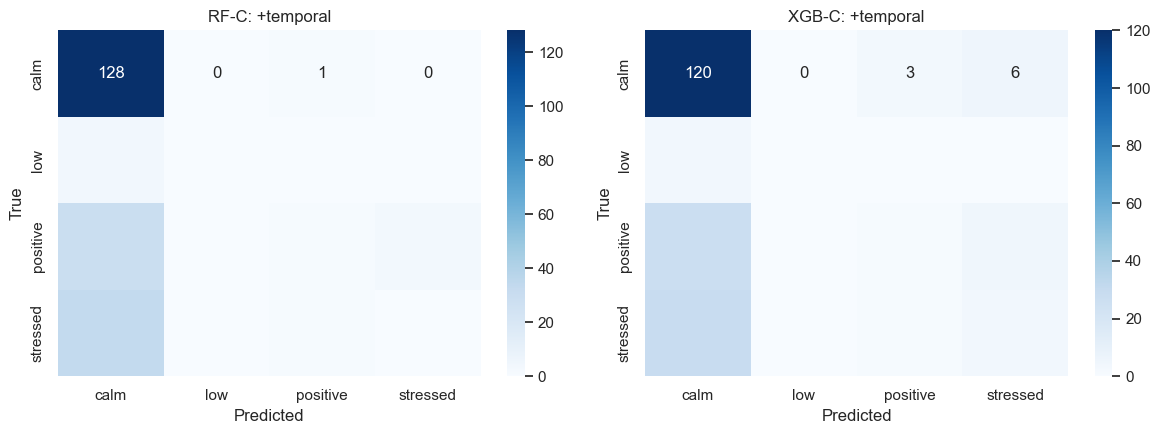

              precision    recall  f1-score   support

        calm       0.67      0.93      0.78       129
         low       0.00      0.00      0.00         4
    positive       0.20      0.03      0.05        33
    stressed       0.27      0.12      0.16        34

    accuracy                           0.62       200
   macro avg       0.28      0.27      0.25       200
weighted avg       0.51      0.62      0.54       200



In [18]:
# SVM comparison on best feature set C (scaled) + confusion matrices for best RF & XGB
scaler = StandardScaler()
Xtr_s = scaler.fit_transform(X_train_full[FEAT_C]); Xte_s = scaler.transform(X_test_full[FEAT_C])
svm = SVC(kernel="rbf", random_state=RANDOM_STATE)
svm.fit(Xtr_s, y_train)
print(evaluate("SVM C: +temporal", y_test, svm.predict(Xte_s)))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for i, key in enumerate([f"RF-C: +temporal", f"XGB-C: +temporal"]):
    if key in trained:
        m, feats = trained[key]
        cm = confusion_matrix(y_test, m.predict(X_test_full[feats]))
        sns.heatmap(cm, annot=True, fmt="d", ax=ax[i], cmap="Blues",
                    xticklabels=le.classes_, yticklabels=le.classes_)
        ax[i].set_title(key); ax[i].set_xlabel("Predicted"); ax[i].set_ylabel("True")
plt.tight_layout(); plt.show()
best_key = "XGB-C: +temporal" if "XGB-C: +temporal" in trained else "RF-C: +temporal"
print(classification_report(y_test, trained[best_key][0].predict(X_test_full[FEAT_C]), target_names=le.classes_))

## 9. Ablation Study (PRD §19–20: A vs B vs C)

               model  accuracy  precision_w  recall_w   f1_w
      RF A: raw only     0.630       0.4940     0.630 0.5175
     XGB A: raw only     0.625       0.5413     0.625 0.5539
 RF B: +baseline dev     0.640       0.5304     0.640 0.5378
XGB B: +baseline dev     0.605       0.4763     0.605 0.5143
     RF C: +temporal     0.645       0.4806     0.645 0.5204
    XGB C: +temporal     0.625       0.5083     0.625 0.5374


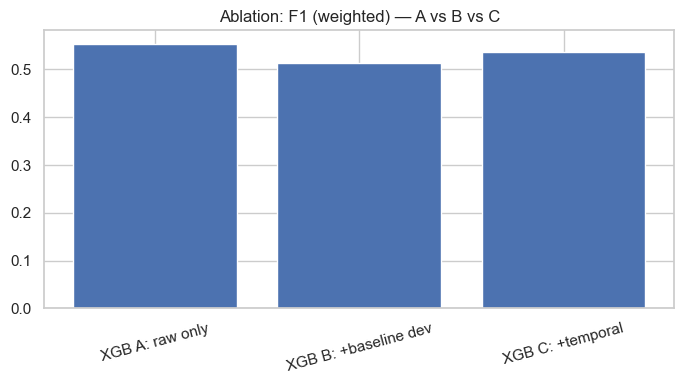

H2 personalization helps if B>A | H3 temporal helps if C>B (on synthetic benchmark only).


In [19]:
abl = res_df.copy()
print(abl.to_string(index=False))
abl_plot = abl[abl["model"].str.startswith("XGB" if HAS_XGB else "RF")]
plt.figure(figsize=(7, 4))
plt.bar(abl_plot["model"], abl_plot["f1_w"])
plt.title("Ablation: F1 (weighted) — A vs B vs C"); plt.xticks(rotation=15); plt.tight_layout(); plt.show()
print("H2 personalization helps if B>A | H3 temporal helps if C>B (on synthetic benchmark only).")

## 10. Explainability — Feature Importance (+optional SHAP) (PRD §17)

Most influential features:
mean_flight_z         0.057047
mean_dwell_z          0.056522
mean_pause_z          0.053151
typing_speed          0.052903
mean_pause            0.052457
mean_flight_change    0.051744
pause_count_change    0.051714
typing_speed_z        0.051572


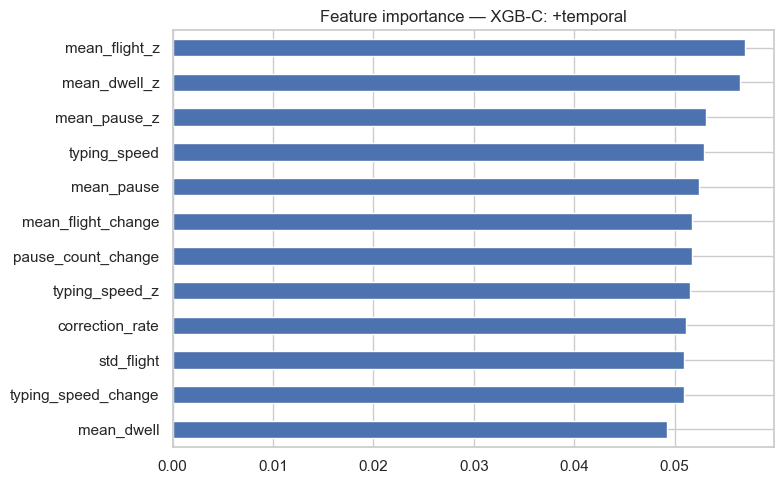

SHAP skipped (optional): No module named 'shap'


In [20]:
best_model, feats = trained[best_key]
imp = pd.Series(best_model.feature_importances_, index=feats).sort_values(ascending=False)
print("Most influential features:"); print(imp.head(8).to_string())
plt.figure(figsize=(8, 5))
imp.head(12).plot(kind="barh"); plt.gca().invert_yaxis()
plt.title(f"Feature importance — {best_key}"); plt.tight_layout(); plt.show()
try:
    import shap
    sv = shap.TreeExplainer(best_model)
    svals = sv.shap_values(X_test_full[feats].iloc[:200])
    shap.summary_plot(svals, X_test_full[feats].iloc[:200], show=True)
except Exception as e:
    print("SHAP skipped (optional):", e)

## 11. LLM Component — Structured Serializer + Prompt + Grounded Explanation (PRD §15–16, R06)
LLM receives ONLY structured features — never typed text.

In [21]:
def build_llm_input(win_row):
    return {
      "current": {k: round(float(win_row[k]), 3) for k in ["typing_speed","mean_dwell","mean_flight","correction_rate"]},
      "baseline_deviation": {k: round(float(win_row[k]), 2) for k in ["typing_speed_z","mean_dwell_z","mean_flight_z","correction_rate_z"]},
      "recent_trend": {"typing_speed_change": round(float(win_row["typing_speed_change"]),3),
                       "pause_change": round(float(win_row["pause_count_change"]),3),
                       "correction_change": round(float(win_row["correction_rate_change"]),3)},
      "ml_prediction": {"state": str(win_row["mood_state"]),
                        "confidence": round(float(max(best_model.predict_proba(X_test_full[feats].iloc[[win_row.name]])[0])), 2)}}
LLM_SYSTEM_PROMPT = ("Given the user's current keystroke statistics, personal baseline deviations, recent trends, and ML prediction, "
    "provide a concise feature-grounded interpretation. Rules: use ONLY supplied numbers; do not invent user info; do not claim certainty; "
    "treat ML prediction as input not truth; state uncertainty; avoid medical diagnosis; never mention typed content.")
ex_row = X_test_full.sample(1, random_state=1).iloc[0]
llm_in = build_llm_input(ex_row)
print("SYSTEM PROMPT:\n", LLM_SYSTEM_PROMPT)
print("\nSTRUCTURED INPUT JSON:\n", json.dumps(llm_in, indent=2))

SYSTEM PROMPT:
 Given the user's current keystroke statistics, personal baseline deviations, recent trends, and ML prediction, provide a concise feature-grounded interpretation. Rules: use ONLY supplied numbers; do not invent user info; do not claim certainty; treat ML prediction as input not truth; state uncertainty; avoid medical diagnosis; never mention typed content.

STRUCTURED INPUT JSON:
 {
  "current": {
    "typing_speed": 7.007,
    "mean_dwell": 119.401,
    "mean_flight": 175.381,
    "correction_rate": 0.03
  },
  "baseline_deviation": {
    "typing_speed_z": -0.5,
    "mean_dwell_z": 0.83,
    "mean_flight_z": 1.42,
    "correction_rate_z": -0.36
  },
  "recent_trend": {
    "typing_speed_change": -1.154,
    "pause_change": 2.667,
    "correction_change": -0.01
  },
  "ml_prediction": {
    "state": "calm",
    "confidence": 0.46
  }
}


In [22]:
# Offline feature-grounded explainer (works WITHOUT API key; swap with OpenAI call when available)
def grounded_explanation(d):
    c, z, t, ml = d["current"], d["baseline_deviation"], d["recent_trend"], d["ml_prediction"]
    feats = []
    feats.append(f"typing {c['typing_speed']} keys/s ({z['typing_speed_z']:+.1f} SD vs baseline)")
    feats.append(f"dwell {c['mean_dwell']} ms ({z['mean_dwell_z']:+.1f} SD)")
    feats.append(f"flight {c['mean_flight']} ms ({z['mean_flight_z']:+.1f} SD)")
    feats.append(f"correction rate {c['correction_rate']:.1%} ({z['correction_rate_z']:+.1f} SD)")
    trend = ("slowing" if t["typing_speed_change"]<0 else "speeding") + f" trend ({t['typing_speed_change']:+.2f})"
    return {"predicted_state": ml["state"], "confidence": "moderate" if ml["confidence"]<0.85 else "high",
        "explanation": (f"Model predicted '{ml['state']}' (p={ml['confidence']}) mainly because " + "; ".join(feats)
            + f", with a {trend}. This is a behavioural deviation from the user's own baseline, not a diagnosis, and uncertainty remains."),
        "important_features": feats}
print(json.dumps(grounded_explanation(llm_in), indent=2))
# --- Optional live LLM call (needs OPENAI_API_KEY) ---
# from openai import OpenAI; client = OpenAI()
# resp = client.chat.completions.create(model="gpt-4o-mini",
#   messages=[{"role":"system","content":LLM_SYSTEM_PROMPT},
#             {"role":"user","content":json.dumps(llm_in)}])
# print(resp.choices[0].message.content)

{
  "predicted_state": "calm",
  "confidence": "moderate",
  "explanation": "Model predicted 'calm' (p=0.46) mainly because typing 7.007 keys/s (-0.5 SD vs baseline); dwell 119.401 ms (+0.8 SD); flight 175.381 ms (+1.4 SD); correction rate 3.0% (-0.4 SD), with a slowing trend (-1.15). This is a behavioural deviation from the user's own baseline, not a diagnosis, and uncertainty remains.",
  "important_features": [
    "typing 7.007 keys/s (-0.5 SD vs baseline)",
    "dwell 119.401 ms (+0.8 SD)",
    "flight 175.381 ms (+1.4 SD)",
    "correction rate 3.0% (-0.4 SD)"
  ]
}


## 12. Save Outputs + Dashboard Preview (PRD §18)

In [23]:
os.makedirs("models", exist_ok=True)
win_df.to_csv("window_features.csv", index=False)
with open("models/best_model.pkl","wb") as f: pickle.dump({"model": best_model, "features": feats, "labels": list(le.classes_)}, f)
# Dashboard-style console preview for one test window
r = X_test_full.iloc[0]
print(f"Predicted State: {str(r['mood_state']).upper()} | Privacy: Typed content NOT COLLECTED")
print(f"Typing {r['typing_speed']:.1f} keys/s | Dwell {r['mean_dwell']:.0f}ms | Flight {r['mean_flight']:.0f}ms | Corr {r['correction_rate']:.0%}")
print(f"Speed {r['typing_speed_z']:+.1f} SD | Dwell {r['mean_dwell_z']:+.1f} SD | Flight {r['mean_flight_z']:+.1f} SD | Corr {r['correction_rate_z']:+.1f} SD")
print("\nExplanation:", grounded_explanation(build_llm_input(r))["explanation"])
print("\nSaved: window_features.csv, models/best_model.pkl")

Predicted State: POSITIVE | Privacy: Typed content NOT COLLECTED
Typing 8.6 keys/s | Dwell 101ms | Flight 117ms | Corr 5%
Speed -0.0 SD | Dwell +1.1 SD | Flight -0.1 SD | Corr +0.6 SD

Explanation: Model predicted 'positive' (p=0.78) mainly because typing 8.596 keys/s (-0.0 SD vs baseline); dwell 101.174 ms (+1.1 SD); flight 117.136 ms (-0.1 SD); correction rate 5.0% (+0.6 SD), with a speeding trend (+0.00). This is a behavioural deviation from the user's own baseline, not a diagnosis, and uncertainty remains.

Saved: window_features.csv, models/best_model.pkl


## Conclusion — Viva Notes (PRD §25–29)
- **H1:** Behavioural features separate synthetic states (see confusion matrix / F1). **H2:** B vs A tests personalization. **H3:** C vs B tests temporal gain. **H4:** LLM gives understandable feature-grounded text without typed content.
- **Limitation:** All accuracy = *synthetic benchmark only*; no clinical claim. Future: real participants + self-reported valence/arousal, LOUO validation. (Streamlit dashboard: render §12 preview + `grounded_explanation()` in `app/dashboard.py`.)

In [28]:
from google import genai

client = genai.Client(api_key="AQ.Ab8RN6K1Nwi6u8lnHFp7BuQmJnUcVYl6UBXghx2Q80hD9A9e5w")  # set env var first

resp = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    config={"system_instruction": LLM_SYSTEM_PROMPT},
    contents=json.dumps(llm_in),
)
print(resp.text)

Based on the current keystroke metrics, typing speed is moderately below baseline (z = -0.5), with a recent downward trend of -1.154. Both mean dwell time (z = 0.83) and mean flight time (z = 1.42) show elevations above baseline, accompanied by an increase in pauses (2.667). The correction rate remains slightly below baseline (z = -0.36) with little recent change (-0.01). 

The machine learning model predicts a "calm" state, though with low confidence (0.46). Given the conflicting signals—slower, more hesitant timing metrics alongside low correction activity—these patterns remain difficult to interpret with certainty and do not point to a definitive state.


In [25]:
%pip install -U google-genai

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
aiogram 3.17.0 requires pydantic<2.11,>=2.4.1, but you have pydantic 2.13.5 which is incompatible.
preswald 0.1.50 requires websockets<11.0,>=10.0; platform_system != "Emscripten", but you have websockets 16.1.1 which is incompatible.
stagesepx 0.18.3 requires pydantic==1.*, but you have pydantic 2.13.5 which is incompatible.
streamlit 1.36.0 requires packaging<25,>=20, but you have packaging 25.0 which is incompatible.
streamlit 1.36.0 requires pandas<3,>=1.3.0, but you have pandas 3.0.2 which is incompatible.
streamlit 1.36.0 requires tenacity<9,>=8.1.0, but you have tenacity 9.1.4 which is incompatible.
tensorflow-intel 2.18.0 requires ml-dtypes<0.5.0,>=0.4.0, but you have ml-dtypes 0.5.3 which is


   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   -------- ------------------------------- 0.3/1.2 MB ? eta -:--:--
   -------------------------- ------------- 0.8/1.2 MB 2.4 MB/s eta 0:00:01
   ---------------------------------------- 1.2/1.2 MB 1.8 MB/s  0:00:00
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 699.0 kB/s eta 0:00:03
   --------------- ------------------------ 0.8/2.0 MB 882.6 kB/s eta 0:00:02
   ------------------------- -------------- 1.3/2.0 MB 1.3 MB/s eta 0:00:01
   ------------------------- -------------- 1.3/2.0 MB 1.3 MB/s et